# Homework 5
Name: Hao Pang; ID: 6495868529; Course: DSCI 552

## 1. Decision Trees as Interpretable Models
### (a) Load and prepare the data

In [1]:
import pandas as pd

columns = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pain",
    "urethra_burning",
    "bladder_inflammation",
    "nephritis"
]

diagnosis = pd.read_csv(
    "diagnosis.data",
    sep="\t",
    header=None,
    names=columns,
    encoding="utf-16",
    decimal=","
)

for column in columns[1:]:
    diagnosis[column] = diagnosis[column].map({"no": 0, "yes": 1})

print("Data shape:", diagnosis.shape)
print("Missing values:", diagnosis.isna().sum().sum())
diagnosis.head()

Data shape: (120, 8)
Missing values: 0


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,urethra_burning,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build and plot a decision tree

I combine the two diagnosis labels into four classes using the label powerset method. The tree is trained on the whole dataset.

**Why label powerset?** The two diagnoses can occur together, so the labels are not independent. Label powerset treats each label combination as one class, so the tree can learn the joint pattern directly. Binary relevance would build one tree per label and ignore the relationship between them. Here there are only four possible combinations and all of them appear in the data, so the powerset classes are not too sparse. Therefore, label powerset is the more suitable approach for this data set.

Tree depth: 4
Number of leaves: 6
Training accuracy: 1.000


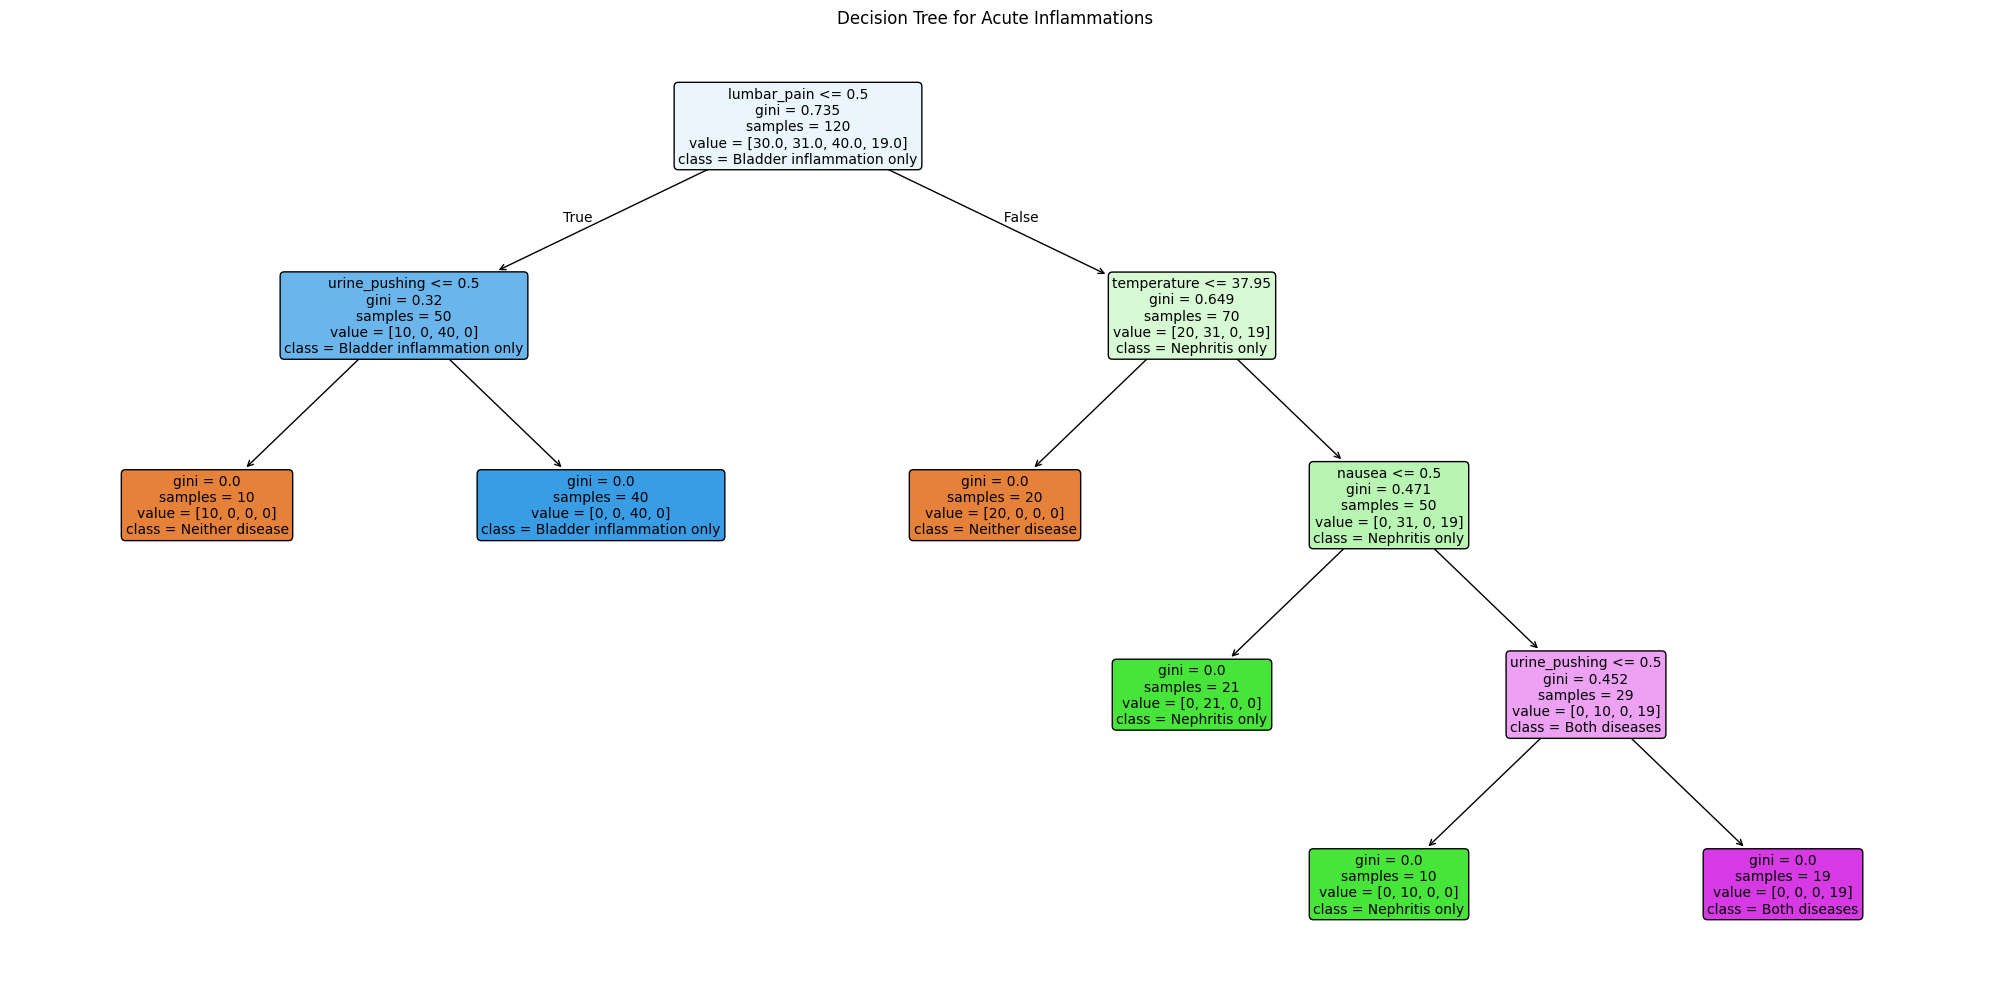

In [2]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

X = diagnosis.iloc[:, :6].copy()
y = 2 * diagnosis["bladder_inflammation"] + diagnosis["nephritis"]

class_names = [
    "Neither disease",
    "Nephritis only",
    "Bladder inflammation only",
    "Both diseases"
]

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X, y)

print("Tree depth:", tree.get_depth())
print("Number of leaves:", tree.get_n_leaves())
print(f"Training accuracy: {tree.score(X, y):.3f}")

plt.figure(figsize=(20, 10))
plot_tree(
    tree,
    feature_names=X.columns.tolist(),
    class_names=[class_names[int(c)] for c in tree.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree for Acute Inflammations")
plt.tight_layout()
plt.show()

### (c) Convert the tree into IF-THEN rules

Each path from the root to a leaf gives one decision rule. The tree has six leaves, so there are six rules.

In [3]:
def print_rules(model, feature_names, class_names):
    structure = model.tree_

    def walk(node, conditions):
        left = structure.children_left[node]
        right = structure.children_right[node]

        if left == right:
            class_index = structure.value[node][0].argmax()
            label = int(model.classes_[class_index])
            print("IF " + " AND ".join(conditions))
            print("THEN " + class_names[label] + "\n")
            return

        feature = feature_names[structure.feature[node]]
        threshold = structure.threshold[node]

        if feature == "temperature":
            left_condition = f"{feature} <= {threshold:.2f}"
            right_condition = f"{feature} > {threshold:.2f}"
        else:
            left_condition = f"{feature} = no"
            right_condition = f"{feature} = yes"

        walk(left, conditions + [left_condition])
        walk(right, conditions + [right_condition])

    walk(0, [])


print_rules(tree, X.columns.tolist(), class_names)

IF lumbar_pain = no AND urine_pushing = no
THEN Neither disease

IF lumbar_pain = no AND urine_pushing = yes
THEN Bladder inflammation only

IF lumbar_pain = yes AND temperature <= 37.95
THEN Neither disease

IF lumbar_pain = yes AND temperature > 37.95 AND nausea = no
THEN Nephritis only

IF lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = no
THEN Nephritis only

IF lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = yes
THEN Both diseases



### (d) Cost-complexity pruning

I use five-fold cross-validation to compare pruning parameters. Using the one-standard-error rule, I choose the simplest candidate tree whose mean accuracy is within one standard error of the best score.

In [4]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score

path = tree.cost_complexity_pruning_path(X, y)
alphas = np.unique(path.ccp_alphas)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for alpha in alphas:
    model = DecisionTreeClassifier(
        ccp_alpha=alpha,
        random_state=42
    )

    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    model.fit(X, y)

    results.append({
        "alpha": alpha,
        "leaves": model.get_n_leaves(),
        "depth": model.get_depth(),
        "cv_accuracy": scores.mean(),
        "cv_se": scores.std(ddof=1) / np.sqrt(len(scores)),
        "training_accuracy": model.score(X, y)
    })

pruning_results = pd.DataFrame(results)
display(pruning_results.round(4))

best_index = pruning_results["cv_accuracy"].idxmax()
cutoff = (
    pruning_results.loc[best_index, "cv_accuracy"]
    - pruning_results.loc[best_index, "cv_se"]
)

eligible = pruning_results[
    pruning_results["cv_accuracy"] >= cutoff
]

selected = eligible.sort_values(
    ["leaves", "alpha"],
    ascending=[True, False]
).iloc[0]

best_alpha = float(selected["alpha"])

pruned_tree = DecisionTreeClassifier(
    ccp_alpha=best_alpha,
    random_state=42
)
pruned_tree.fit(X, y)

print(f"Selected alpha: {best_alpha:.6f}")
print("Tree depth:", pruned_tree.get_depth())
print("Number of leaves:", pruned_tree.get_n_leaves())
print(f"Training accuracy: {pruned_tree.score(X, y):.3f}")

,alpha,leaves,depth,cv_accuracy,cv_se,training_accuracy
0,0.0000,6,4,0.9917,0.0083,1.0000
1,0.0982,4,2,0.8583,0.0250,0.8417
2,0.1333,3,2,0.7583,0.0333,0.7583
3,0.1820,2,1,0.6667,0.0295,0.5917
4,0.2229,1,0,0.4833,0.0612,0.3333


Selected alpha: 0.000000
Tree depth: 4
Number of leaves: 6
Training accuracy: 1.000


The selected ccp_alpha is 0, so under the one-standard-error rule the tree remains unchanged. Its mean cross-validation accuracy is 99.17%, which is much higher than the next candidate.

To show what pruning would give, I also fit the next tree on the pruning path (four leaves) and print its rules below.

alpha: 0.0982
Tree depth: 2
Number of leaves: 4
Training accuracy: 0.842



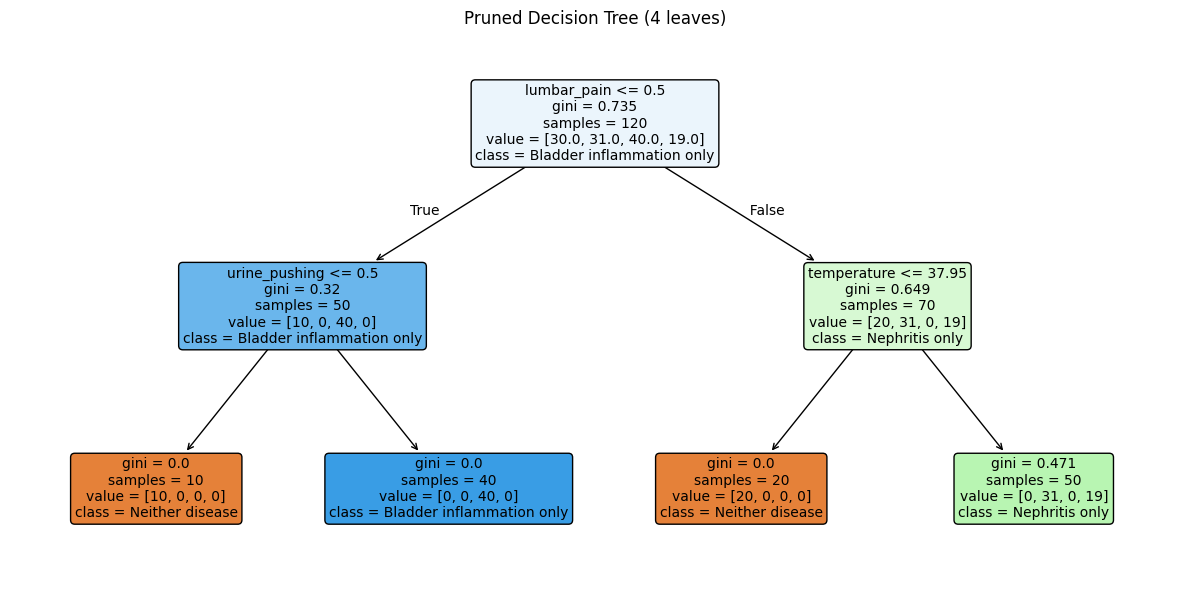

IF lumbar_pain = no AND urine_pushing = no
THEN Neither disease

IF lumbar_pain = no AND urine_pushing = yes
THEN Bladder inflammation only

IF lumbar_pain = yes AND temperature <= 37.95
THEN Neither disease

IF lumbar_pain = yes AND temperature > 37.95
THEN Nephritis only



In [5]:
alpha_4 = float(pruning_results.loc[pruning_results["leaves"] == 4, "alpha"].iloc[0])

tree_4 = DecisionTreeClassifier(ccp_alpha=alpha_4, random_state=42)
tree_4.fit(X, y)

print(f"alpha: {alpha_4:.4f}")
print("Tree depth:", tree_4.get_depth())
print("Number of leaves:", tree_4.get_n_leaves())
print(f"Training accuracy: {tree_4.score(X, y):.3f}\n")

plt.figure(figsize=(12, 6))
plot_tree(
    tree_4,
    feature_names=X.columns.tolist(),
    class_names=[class_names[int(c)] for c in tree_4.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Pruned Decision Tree (4 leaves)")
plt.tight_layout()
plt.show()

print_rules(tree_4, X.columns.tolist(), class_names)

**Conclusion.** The four-leaf tree is easier to read, but its cross-validation accuracy drops from 99.17% to 85.83% and it cannot identify patients with both diseases. The six-leaf tree uses only four features (lumbar_pain, urine_pushing, temperature, nausea) and gives six short rules, so it is already highly interpretable. I therefore select the unpruned six-leaf tree (ccp_alpha = 0) as the minimal tree that keeps high accuracy.

## 2. The LASSO and Boosting for Regression
### (a) Load and split the data

The first 1,495 rows are used for training, and the remaining rows are used for testing.

In [6]:
with open("communities.names", encoding="utf-8") as file:
    crime_columns = [
        line.split()[1]
        for line in file
        if line.strip().lower().startswith("@attribute")
    ]

crime = pd.read_csv(
    "communities.data",
    header=None,
    names=crime_columns,
    na_values="?"
)

crime_train = crime.iloc[:1495].copy()
crime_test = crime.iloc[1495:].copy()

print("Full dataset:", crime.shape)
print("Training set:", crime_train.shape)
print("Test set:", crime_test.shape)

Full dataset: (1994, 128)
Training set: (1495, 128)
Test set: (499, 128)


### (b) Remove nonpredictive features and impute missing values

I remove state, county, community, communityname, and fold because they are nonpredictive identifiers. Missing predictor values are filled with the training-set medians. The same medians are used for the test set.

Note that 22 police-related (LEMAS) features are missing for about 84% of communities. After median imputation, most values in these columns are the same constant. This is a limitation of simple imputation; adding missing-value indicators or dropping these columns would be alternatives.

In [7]:
from sklearn.impute import SimpleImputer

nonpredictive = [
    "state", "county", "community", "communityname", "fold"
]
target = "ViolentCrimesPerPop"

X_train_raw = crime_train.drop(columns=nonpredictive + [target])
X_test_raw = crime_test.drop(columns=nonpredictive + [target])

y_train = crime_train[target].copy()
y_test = crime_test[target].copy()

print("Missing training values before imputation:",
      X_train_raw.isna().sum().sum())
print("Missing test values before imputation:",
      X_test_raw.isna().sum().sum())

imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train_raw),
    columns=X_train_raw.columns,
    index=X_train_raw.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=X_test_raw.columns,
    index=X_test_raw.index
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Missing training values after imputation:",
      X_train.isna().sum().sum())
print("Missing test values after imputation:",
      X_test.isna().sum().sum())
print("Missing target values:", y_train.isna().sum() + y_test.isna().sum())

Missing training values before imputation: 27633
Missing test values before imputation: 9218
Training features: (1495, 122)
Test features: (499, 122)
Missing training values after imputation: 0
Missing test values after imputation: 0
Missing target values: 0


### (c) Correlation matrix

I plot the Pearson correlation matrix of the 122 predictors using the imputed training data.

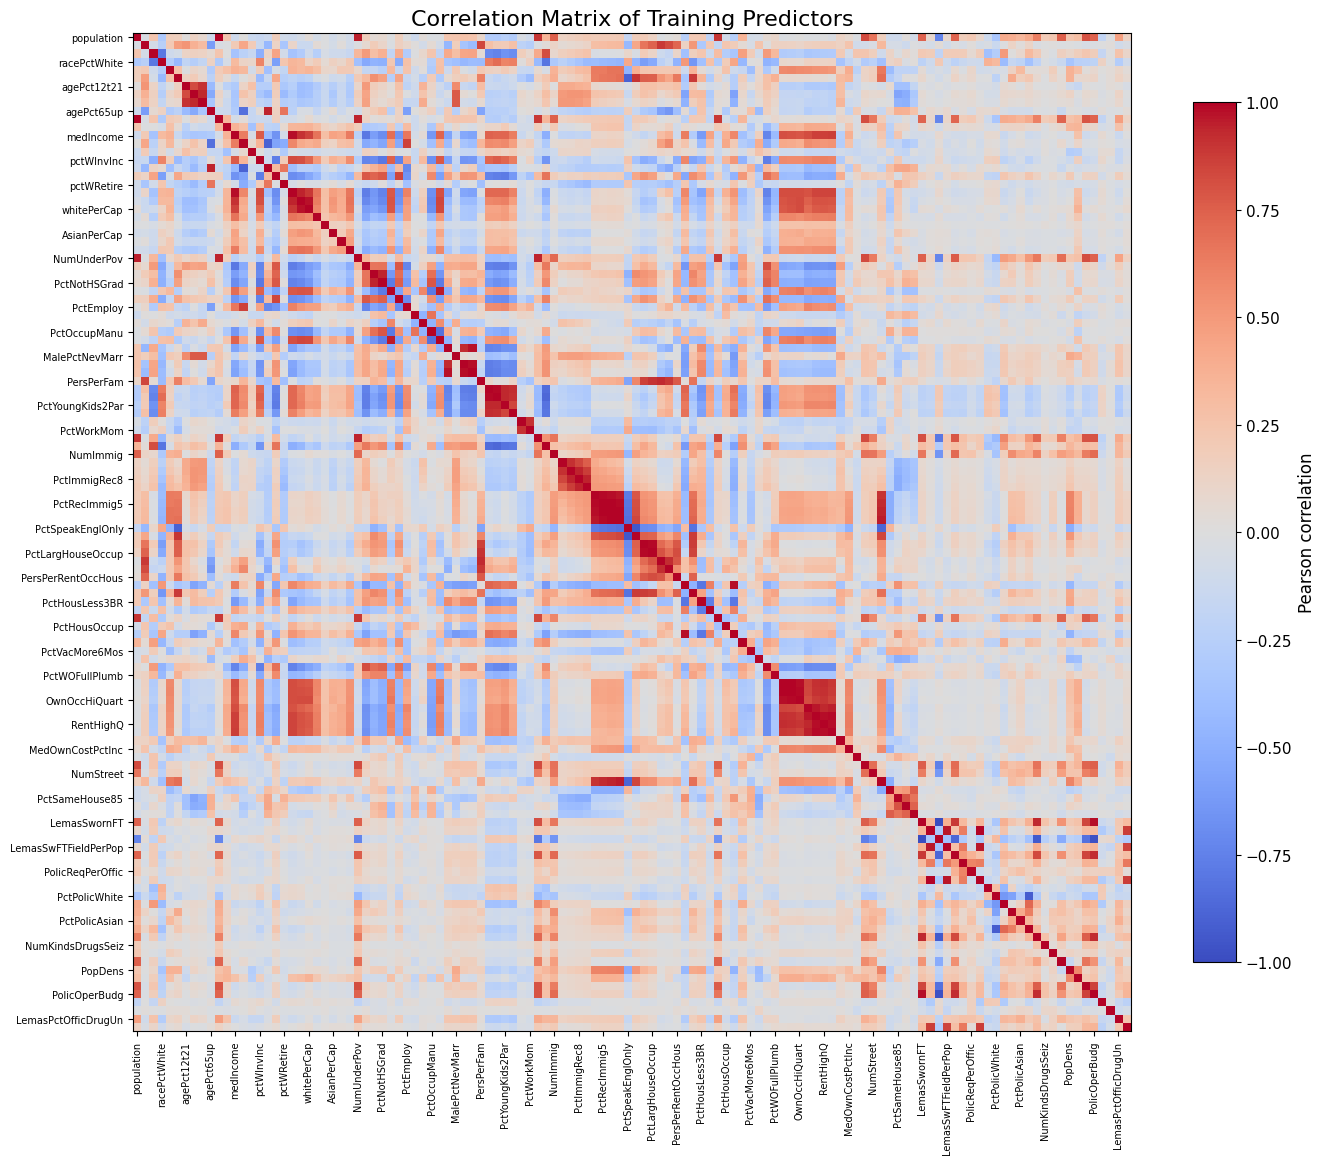

In [8]:
correlation = X_train.corr()

fig, ax = plt.subplots(figsize=(14, 12))

heatmap = ax.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    interpolation="nearest"
)

positions = np.arange(0, len(correlation.columns), 3)
labels = correlation.columns[positions]

ax.set_xticks(positions)
ax.set_yticks(positions)
ax.set_xticklabels(labels, rotation=90, fontsize=7)
ax.set_yticklabels(labels, fontsize=7)

colorbar = fig.colorbar(heatmap, ax=ax, shrink=0.8)
colorbar.set_label("Pearson correlation", fontsize=12)
colorbar.ax.tick_params(labelsize=11)

ax.set_title("Correlation Matrix of Training Predictors", fontsize=16)

plt.tight_layout()
plt.show()

### (d) Coefficient of variation

I calculate the coefficient of variation for each predictor using the imputed training data. CV is the sample standard deviation divided by the mean.

In [9]:
from textwrap import fill

feature_means = X_train.mean()
feature_stds = X_train.std(ddof=1)

cv_table = pd.DataFrame({
    "mean": feature_means,
    "sample_std": feature_stds,
    "CV": feature_stds / feature_means.replace(0, np.nan)
}).sort_values("CV", ascending=False)
cv_table.index.name = "feature"

cv_text = [f"{name} ({value:.3f})" for name, value in cv_table["CV"].items()]

print("CV of all 122 predictors, sorted from highest to lowest:\n")
print(fill(", ".join(cv_text), width=90))

CV of all 122 predictors, sorted from highest to lowest:

PctPolicAsian (5.527), NumStreet (4.293), NumInShelters (3.471), NumIlleg (3.059),
NumImmig (2.927), LemasPctOfficDrugUn (2.553), NumUnderPov (2.342), LemasSwornFT (2.248),
population (2.241), numbUrban (2.038), HousVacant (1.968), PolicOperBudg (1.646), LandArea
(1.645), racePctHisp (1.612), PctNotSpeakEnglWell (1.457), LemasTotalReq (1.452),
racepctblack (1.429), PctUsePubTrans (1.397), racePctAsian (1.359), PctPolicHisp (1.354),
PctRecentImmig (1.288), PctRecImmig5 (1.286), PctRecImmig10 (1.270), PctRecImmig8 (1.266),
OfficAssgnDrugUnits (1.175), PctPersDenseHous (1.133), PolicCars (1.113), PctForeignBorn
(1.066), PctVacantBoarded (1.055), PctHousNoPhone (0.923), PctIlleg (0.922), OwnOccMedVal
(0.889), OwnOccHiQuart (0.884), PopDens (0.864), OwnOccLowQuart (0.860), PctWOFullPlumb
(0.843), indianPerCap (0.818), MedNumBR (0.814), PctPolicBlack (0.776), PctLargHouseOccup
(0.763), PctPopUnderPov (0.754), PctLargHouseFam (0.739), 

In [10]:
cv_raw = (X_train_raw.std(ddof=1) / X_train_raw.mean()).sort_values(ascending=False)

print("Top 11 CV features after imputation: ", cv_table.head(11).index.tolist())
print("Top 11 CV features before imputation:", cv_raw.head(11).index.tolist())

Top 11 CV features after imputation:  ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'LemasSwornFT', 'population', 'numbUrban', 'HousVacant']
Top 11 CV features before imputation: ['NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'PctPolicAsian', 'HousVacant']


Median imputation changes the mean and standard deviation of the heavily missing LEMAS features, so their CV values are affected. Computing CV on the observed (non-missing) values only gives the same 11 features, just in a slightly different order (for example, PctPolicAsian drops from 1st to 10th). Therefore, the choice of the top 11 features is not sensitive to imputation, and I use the imputed version below.

### (e) Scatter plots and box plots

I select the 11 predictors with the highest CV values. I plot each predictor against the target and use box plots to examine their distributions.

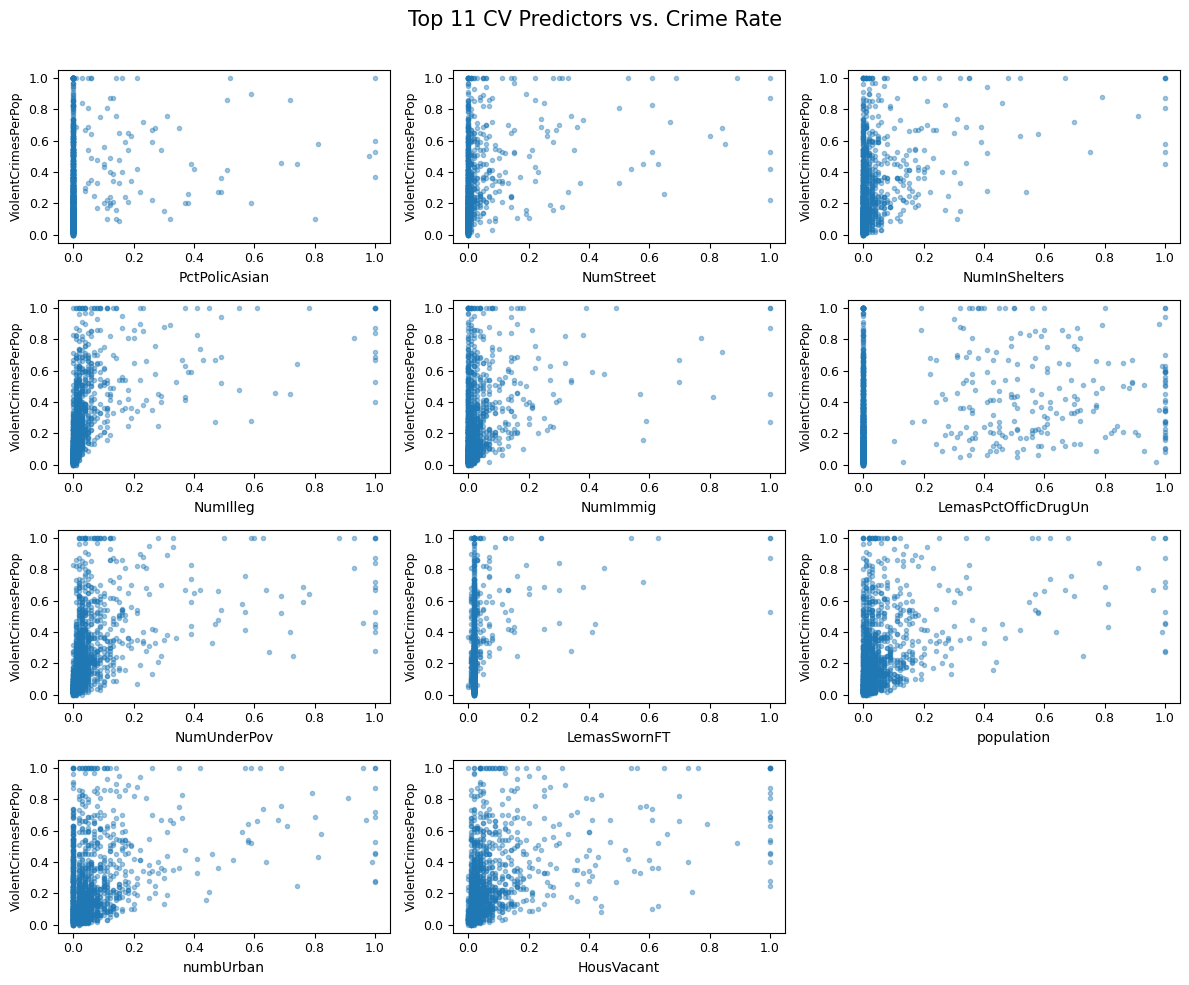

In [11]:
top_features = cv_table["CV"].dropna().head(11).index.tolist()

fig, axes = plt.subplots(4, 3, figsize=(12, 10))
axes = axes.ravel()

for ax, feature in zip(axes, top_features):
    ax.scatter(X_train[feature], y_train, s=9, alpha=0.4)
    ax.set_xlabel(feature, fontsize=10)
    ax.set_ylabel("ViolentCrimesPerPop", fontsize=9)
    ax.tick_params(labelsize=9)

for ax in axes[len(top_features):]:
    ax.set_visible(False)

fig.suptitle("Top 11 CV Predictors vs. Crime Rate", fontsize=15)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


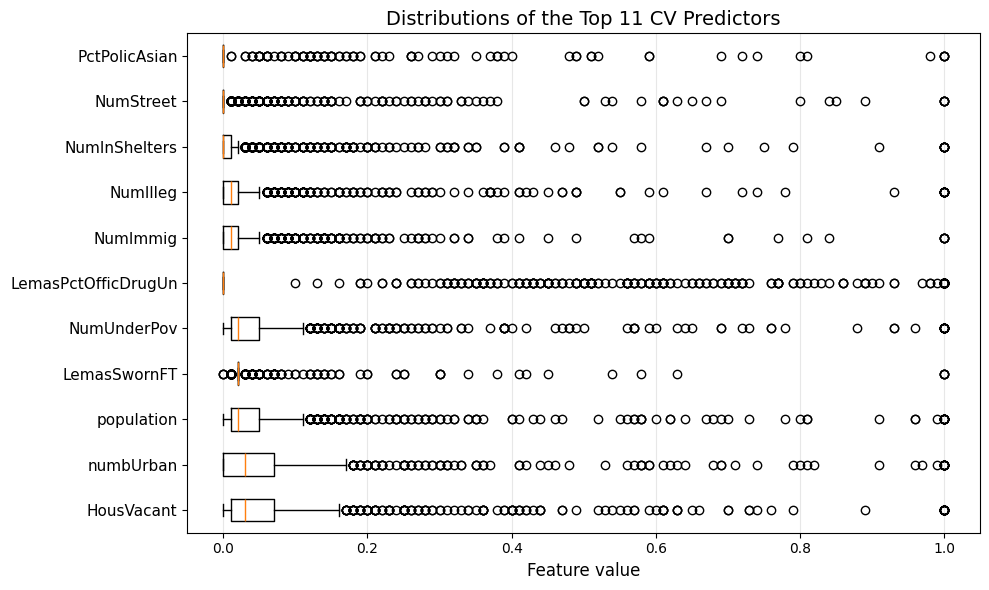

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    [X_train[feature].to_numpy() for feature in top_features],
    vert=False
)

ax.set_yticks(range(1, len(top_features) + 1))
ax.set_yticklabels(top_features, fontsize=11)
ax.invert_yaxis()
ax.set_xlabel("Feature value", fontsize=12)
ax.set_title("Distributions of the Top 11 CV Predictors", fontsize=14)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

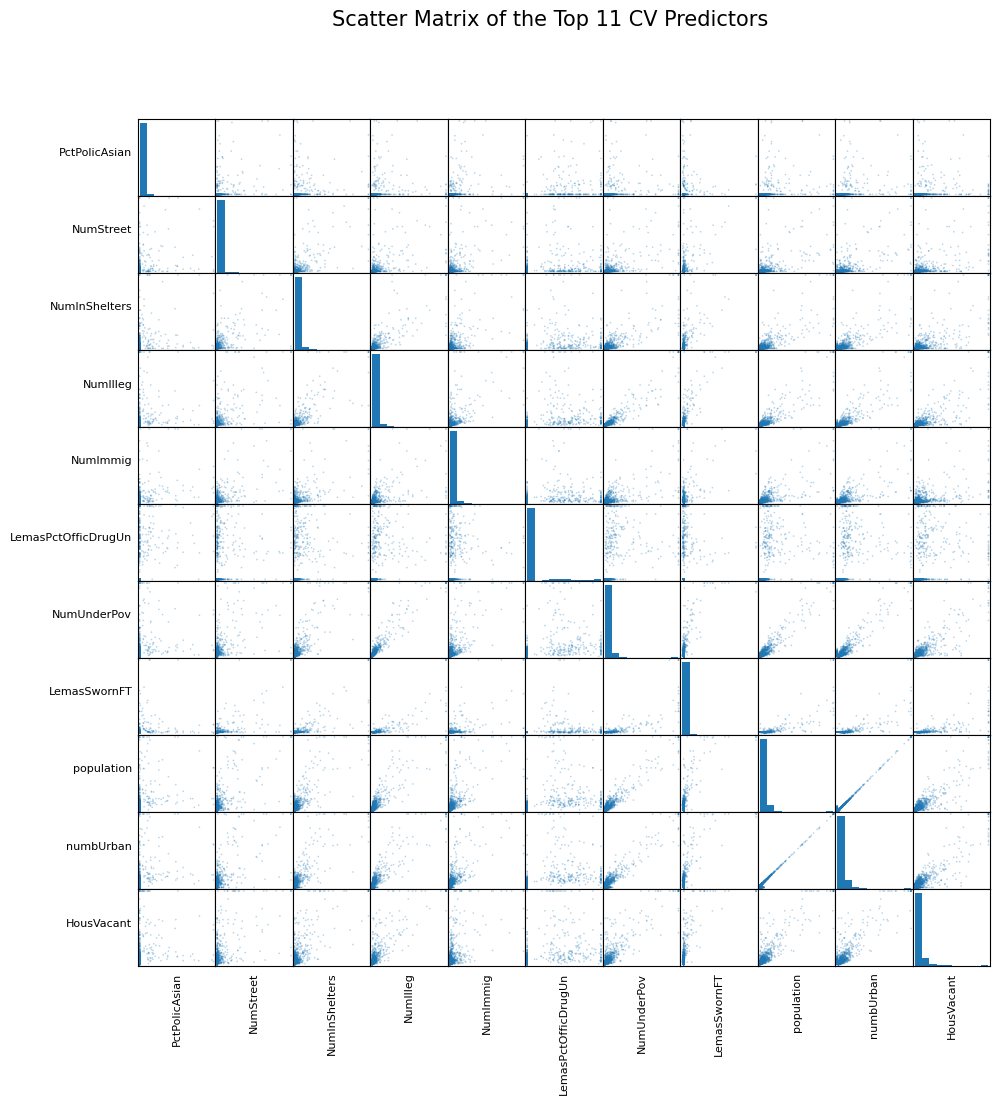

In [13]:
scatter_axes = pd.plotting.scatter_matrix(
    X_train[top_features],
    figsize=(11, 11),
    alpha=0.3,
    s=6,
    diagonal="hist"
)

for ax in scatter_axes.ravel():
    ax.xaxis.label.set_rotation(90)
    ax.yaxis.label.set_rotation(0)
    ax.yaxis.label.set_ha("right")
    ax.xaxis.label.set_fontsize(8)
    ax.yaxis.label.set_fontsize(8)
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle("Scatter Matrix of the Top 11 CV Predictors", fontsize=15)
plt.show()

Most selected predictors are right-skewed, with many small values and some large outliers. Some scatter plots suggest a positive relationship with the crime rate, and the scatter matrix shows that several count features (for example NumStreet, NumIlleg, NumImmig, NumUnderPov and population) are strongly correlated with each other. However, scatter plots alone cannot establish statistical significance: they do not control for the other predictors and do not quantify uncertainty. A high CV also does not necessarily mean that a feature is useful for prediction.

### (f) Least squares regression

I fit a linear regression model using all 122 predictors and report the test mean squared error (MSE).

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

ols = LinearRegression()
ols.fit(X_train, y_train)

ols_predictions = ols.predict(X_test)
ols_mse = mean_squared_error(y_test, ols_predictions)

print(f"OLS test MSE: {ols_mse:.6f}")

OLS test MSE: 0.017966


### (g) Ridge regression

I standardize the predictors and use five-fold cross-validation to select the ridge penalty. Imputation and standardization are fitted separately within each training fold.

In [15]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV

regression_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

ridge_search = GridSearchCV(
    ridge_pipeline,
    param_grid={"ridge__alpha": np.logspace(-4, 4, 81)},
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=1
)

ridge_search.fit(X_train_raw, y_train)

ridge_predictions = ridge_search.predict(X_test_raw)
ridge_mse = mean_squared_error(y_test, ridge_predictions)

print(f"Best ridge alpha: {ridge_search.best_params_['ridge__alpha']:.6f}")
print(f"Best CV MSE: {-ridge_search.best_score_:.6f}")
print(f"Ridge test MSE: {ridge_mse:.6f}")

Best ridge alpha: 125.892541
Best CV MSE: 0.019738
Ridge test MSE: 0.017372


### (h) LASSO regression

#### Without standardization

I use five-fold cross-validation to select the LASSO penalty without standardizing the predictors. Variables with nonzero coefficients are selected by the model.

In [16]:
from textwrap import fill
from sklearn.linear_model import Lasso

lasso_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("lasso", Lasso(max_iter=100000, tol=1e-5))
])

lasso_search = GridSearchCV(
    lasso_pipeline,
    param_grid={"lasso__alpha": np.logspace(-5, 0, 51)},
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=1
)

lasso_search.fit(X_train_raw, y_train)

lasso_predictions = lasso_search.predict(X_test_raw)
lasso_mse = mean_squared_error(y_test, lasso_predictions)

lasso_coefficients = pd.Series(
    lasso_search.best_estimator_.named_steps["lasso"].coef_,
    index=X_train_raw.columns,
    name="coefficient"
)

lasso_selected = lasso_coefficients[lasso_coefficients != 0]
lasso_selected = lasso_selected.loc[
    lasso_selected.abs().sort_values(ascending=False).index
]

print(f"Best LASSO alpha: {lasso_search.best_params_['lasso__alpha']:.8f}")
print(f"Best CV MSE: {-lasso_search.best_score_:.6f}")
print(f"LASSO test MSE: {lasso_mse:.6f}")
print("Number of selected variables:", len(lasso_selected))

print("Selected variables:")
print(fill(", ".join(lasso_selected.index), width=90))


Best LASSO alpha: 0.00012589
Best CV MSE: 0.019521
LASSO test MSE: 0.017615
Number of selected variables: 74
Selected variables:
racepctblack, agePct12t29, PctPersDenseHous, PctKids2Par, NumStreet, RentLowQ, MedRent,
PctPopUnderPov, PctEmploy, PctWorkMom, MalePctNevMarr, HousVacant, MalePctDivorce,
pctWRetire, PctIlleg, pctWInvInc, PolicReqPerOffic, MedRentPctHousInc, NumImmig, NumIlleg,
pctWWage, MedOwnCostPctIncNoMtg, PctVacantBoarded, FemalePctDiv, LemasSwFTFieldPerPop,
PctNotSpeakEnglWell, PctHousOccup, PctVacMore6Mos, agePct12t21, NumInShelters,
PctHousLess3BR, PctPersOwnOccup, whitePerCap, PctLargHouseOccup, PctForeignBorn,
pctWSocSec, PctUsePubTrans, pctUrban, PctYoungKids2Par, pctWPubAsst, LemasGangUnitDeploy,
PctRecImmig10, indianPerCap, PersPerOccupHous, NumKindsDrugsSeiz, AsianPerCap, LandArea,
pctWFarmSelf, PctSameCity85, PctWOFullPlumb, PctHousNoPhone, OtherPerCap, PctPolicAsian,
HispPerCap, blackPerCap, RacialMatchCommPol, PctLess9thGrade, PctEmplManu, racePctAsian,
MedYr

#### With standardization

I repeat LASSO after standardizing the predictors to zero mean and unit variance. Imputation and standardization are fitted within each cross-validation training fold.

In [17]:
lasso_std_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("lasso", Lasso(max_iter=100000, tol=1e-5))
])

lasso_std_search = GridSearchCV(
    lasso_std_pipeline,
    param_grid={"lasso__alpha": np.logspace(-5, 0, 51)},
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=1
)

lasso_std_search.fit(X_train_raw, y_train)

lasso_std_predictions = lasso_std_search.predict(X_test_raw)
lasso_std_mse = mean_squared_error(y_test, lasso_std_predictions)

lasso_std_coefficients = pd.Series(
    lasso_std_search.best_estimator_.named_steps["lasso"].coef_,
    index=X_train_raw.columns,
    name="coefficient"
)

lasso_std_selected = lasso_std_coefficients[
    lasso_std_coefficients != 0
]
lasso_std_selected = lasso_std_selected.loc[
    lasso_std_selected.abs().sort_values(ascending=False).index
]

print(
    f"Best standardized LASSO alpha: "
    f"{lasso_std_search.best_params_['lasso__alpha']:.8f}"
)
print(f"Best CV MSE: {-lasso_std_search.best_score_:.6f}")
print(f"Standardized LASSO test MSE: {lasso_std_mse:.6f}")
print("Number of selected variables:", len(lasso_std_selected))

only_std = sorted(set(lasso_std_selected.index) - set(lasso_selected.index))
only_raw = sorted(set(lasso_selected.index) - set(lasso_std_selected.index))
print("Selected variables: the same as the unstandardized model, except")
print("  added:", ", ".join(only_std))
print("  removed:", ", ".join(only_raw))

Best standardized LASSO alpha: 0.00063096
Best CV MSE: 0.019661
Standardized LASSO test MSE: 0.017722
Number of selected variables: 76
Selected variables: the same as the unstandardized model, except
  added: LemasTotalReq, OfficAssgnDrugUnits, PersPerOwnOccHous
  removed: PctBornSameState


Without standardization, LASSO selects 74 variables and gives a test MSE of 0.017615. With standardization, it selects 76 variables and gives a test MSE of 0.017722. The results are similar, but the model without standardization has a slightly lower test error. Standardization changes the relative penalty on the coefficients and can change which variables are selected. The difference is small because, as the data description notes, the features are already normalized to the range [0, 1], so their scales are already similar before standardization.

### (i) Principal component regression

I use five-fold cross-validation to choose the number of principal components from 1 to 122. Imputation, standardization, and PCA are fitted within each training fold.

In [18]:
from sklearn.decomposition import PCA

pcr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(svd_solver="full")),
    ("regression", LinearRegression())
])

pcr_search = GridSearchCV(
    pcr_pipeline,
    param_grid={
        "pca__n_components": list(range(1, X_train_raw.shape[1] + 1))
    },
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=1
)

pcr_search.fit(X_train_raw, y_train)

pcr_predictions = pcr_search.predict(X_test_raw)
pcr_mse = mean_squared_error(y_test, pcr_predictions)

best_m = pcr_search.best_params_["pca__n_components"]

print("Best number of components:", best_m)
print(f"Best CV MSE: {-pcr_search.best_score_:.6f}")
print(f"PCR test MSE: {pcr_mse:.6f}")

Best number of components: 60
Best CV MSE: 0.020210
PCR test MSE: 0.018350


### (j) XGBoost regression with L1 regularization

In XGBoost, `reg_alpha` adds an L1 penalty on the leaf weights of each tree, which gives an L1-penalized gradient boosting tree. I use five-fold cross-validation to select reg_alpha. The other settings (300 trees, learning rate 0.05, maximum depth 3) are fixed by choice and not tuned, so that the comparison focuses on the L1 penalty.

In [19]:
from xgboost import XGBRegressor

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBRegressor(
        objective="reg:squarederror",
        booster="gbtree",
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        tree_method="hist",
        random_state=42,
        n_jobs=1
    ))
])

xgb_search = GridSearchCV(
    xgb_pipeline,
    param_grid={
        "xgb__reg_alpha": [0.0] + np.logspace(-4, 2, 13).tolist()
    },
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=1
)

xgb_search.fit(X_train_raw, y_train)

xgb_predictions = xgb_search.predict(X_test_raw)
xgb_mse = mean_squared_error(y_test, xgb_predictions)

print(f"Best XGBoost alpha: {xgb_search.best_params_['xgb__reg_alpha']:.6f}")
print(f"Best CV MSE: {-xgb_search.best_score_:.6f}")
print(f"XGBoost test MSE: {xgb_mse:.6f}")

Best XGBoost alpha: 0.100000
Best CV MSE: 0.019907
XGBoost test MSE: 0.016422


## Model Comparison

In [20]:
comparison = pd.DataFrame({
    "Model": [
        "OLS",
        "Ridge",
        "LASSO without standardization",
        "LASSO with standardization",
        "PCR",
        "XGBoost"
    ],
    "Test MSE": [
        ols_mse,
        ridge_mse,
        lasso_mse,
        lasso_std_mse,
        pcr_mse,
        xgb_mse
    ]
})

display(comparison.round(6))

,Model,Test MSE
0,OLS,0.017966
1,Ridge,0.017372
2,LASSO without standardization,0.017615
3,LASSO with standardization,0.017722
4,PCR,0.018350
5,XGBoost,0.016422


XGBoost has the lowest test MSE among the six fitted models. Ridge also improves on OLS. The two LASSO models have similar test errors, with the unstandardized version performing slightly better. PCR uses 60 components but has the highest test MSE in this comparison.